Berhasil! File 'ambient_noise_tomography_result.png' siap digunakan.


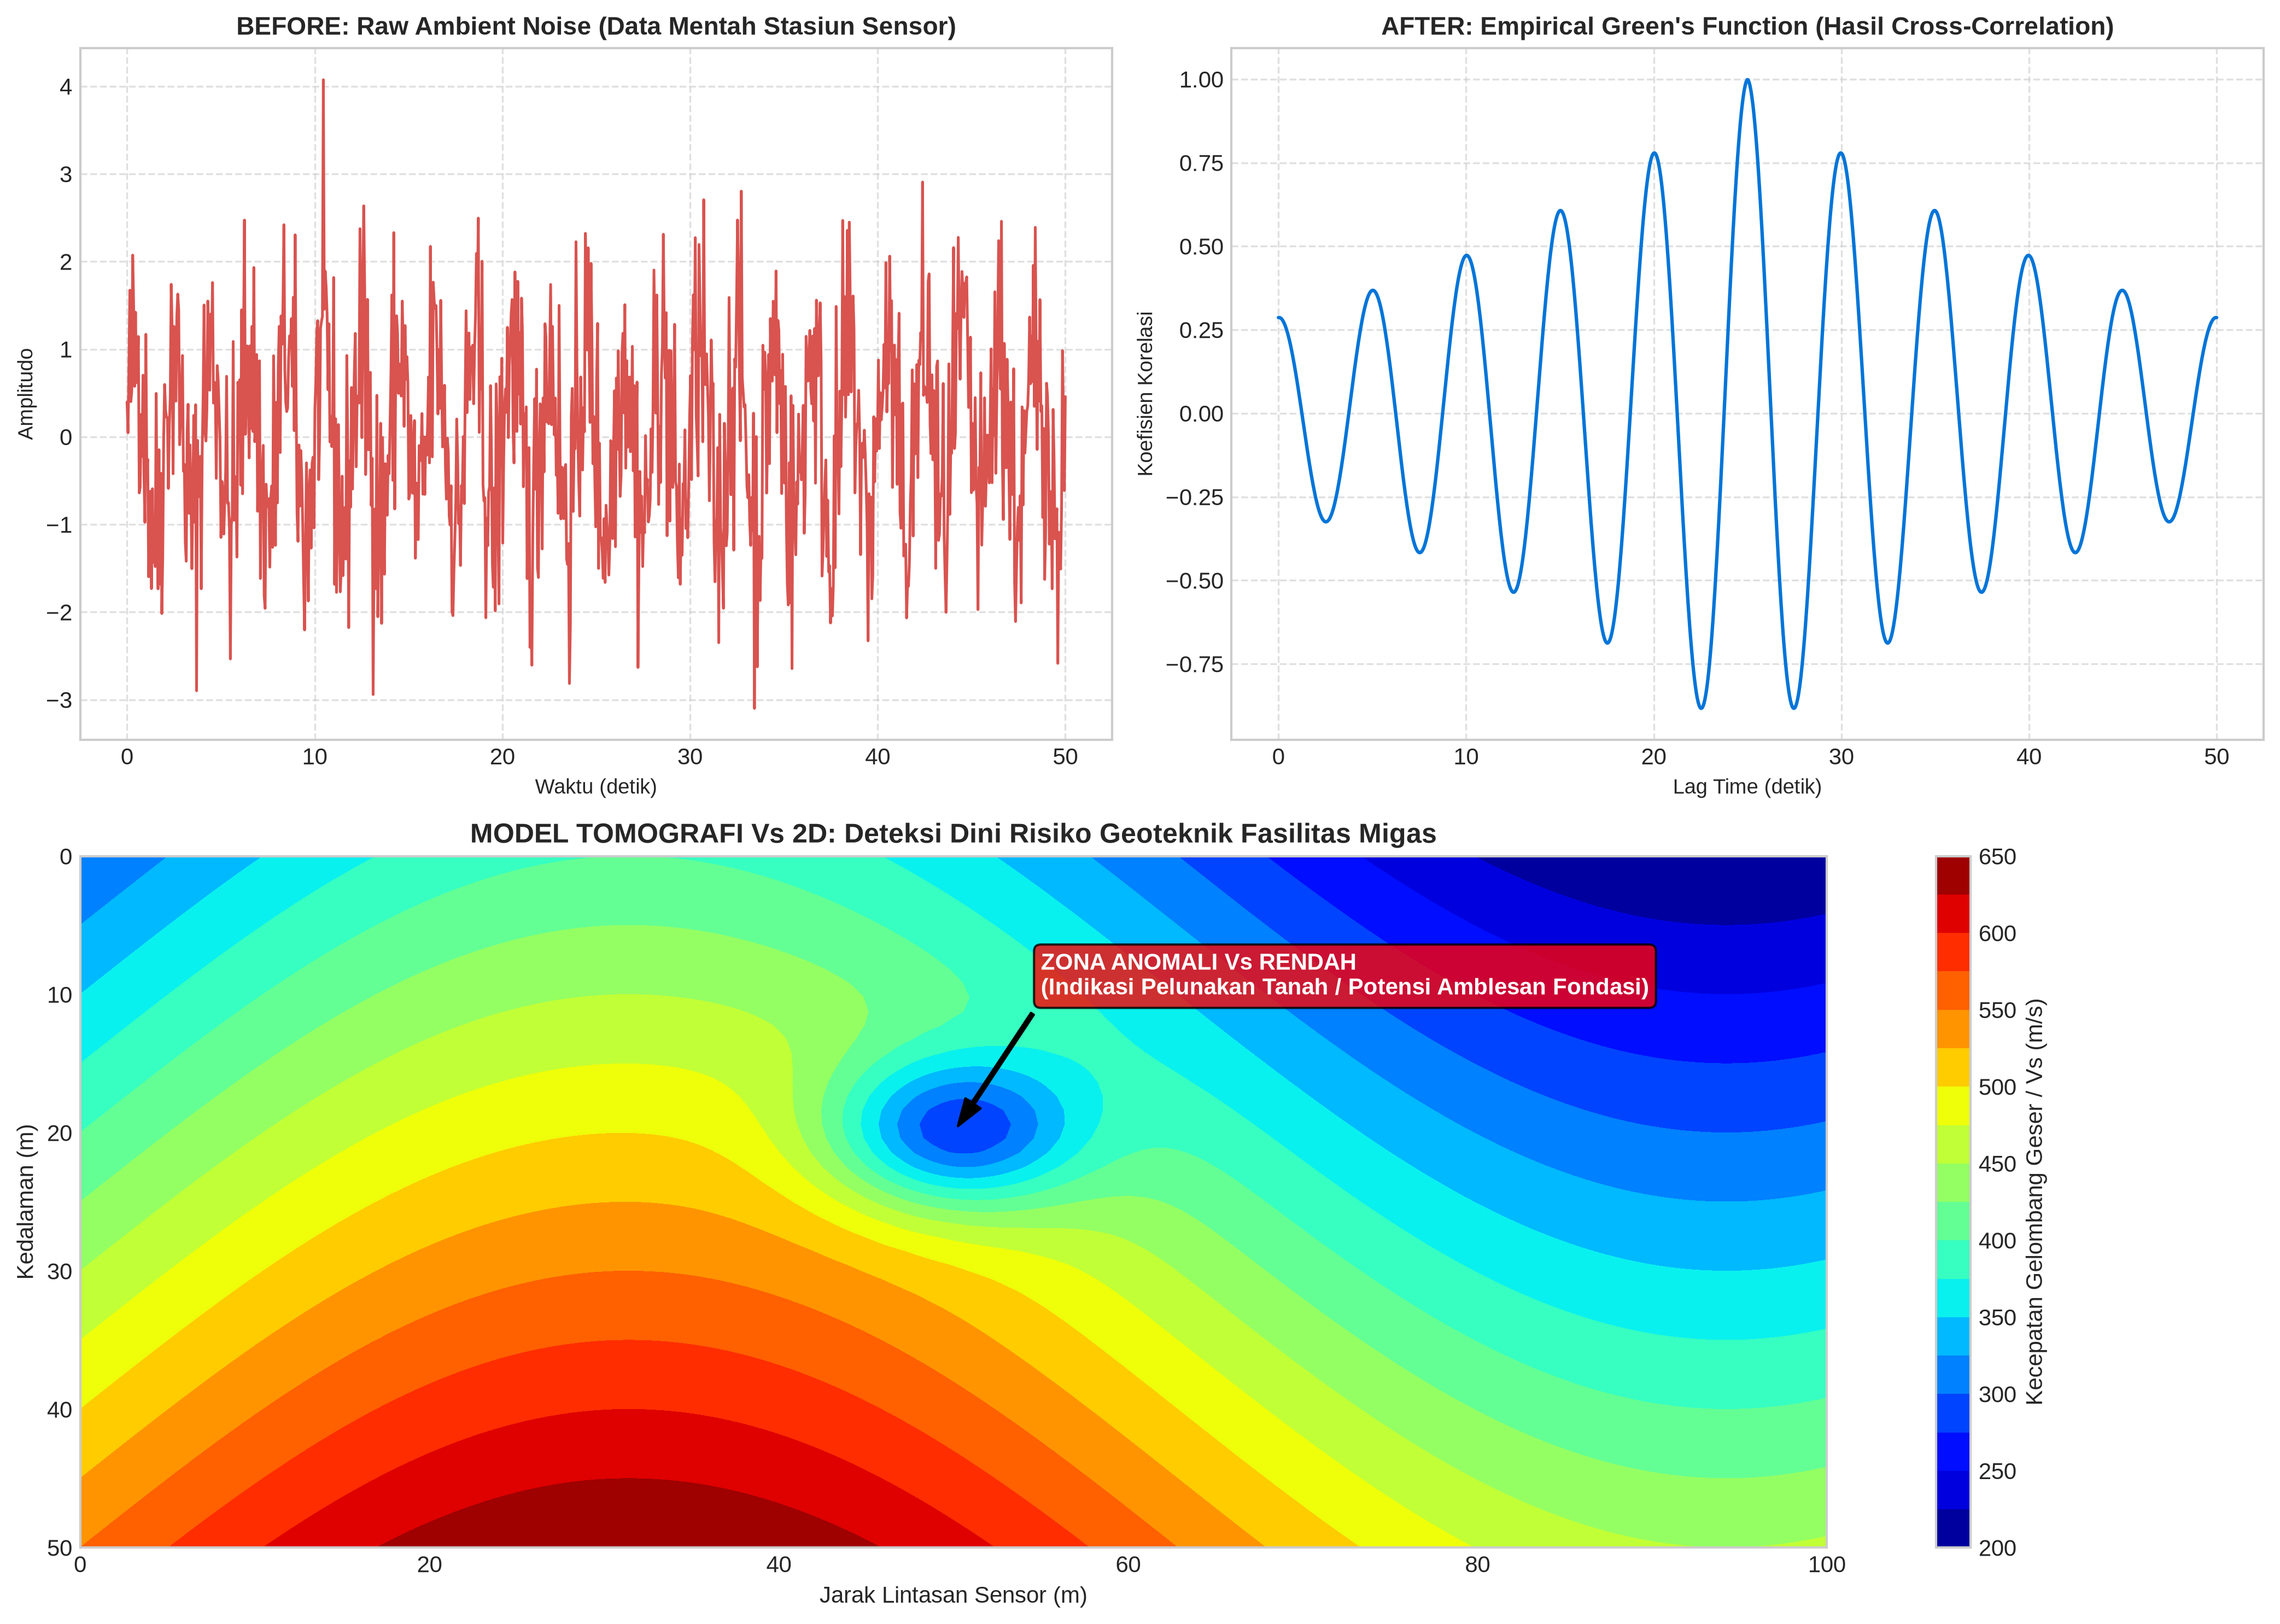

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from obspy import Stream, Trace

# Konfigurasi style plot agar estetik dan profesional untuk poster
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig = plt.figure(figsize=(14, 10), dpi=300)

# ==========================================
# 1. PLOT BAGIAN ATAS: BEFORE vs AFTER (SIGNAL PROCESSING)
# ==========================================
# Mensimulasikan data raw ambient noise vs hasil cross-correlation (Green's Function)
t = np.linspace(0, 50, 1000)
# Raw ambient noise (random acak / bising)
np.random.seed(42)
raw_noise = np.sin(2 * np.pi * 0.5 * t) + 0.8 * np.random.randn(len(t))
# Cross-correlation result (Green's Function yang koheren / bersih)
greens_func = np.exp(-0.05 * np.abs(t - 25)) * np.cos(
    2 * np.pi * 0.2 * (t - 25)
)

# Subplot 1: Raw Ambient Noise (Before)
ax1 = plt.subplot(2, 2, 1)
ax1.plot(t, raw_noise, color="#d9534f", lw=1.2)
ax1.set_title(
    "BEFORE: Raw Ambient Noise (Data Mentah Stasiun Sensor)",
    fontsize=11,
    fontweight="bold",
)
ax1.set_xlabel("Waktu (detik)", fontsize=9)
ax1.set_ylabel("Amplitudo", fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.6)

# Subplot 2: Cross-Correlation / Empirical Green's Function (After)
ax2 = plt.subplot(2, 2, 2)
ax2.plot(t, greens_func, color="#0275d8", lw=1.5)
ax2.set_title(
    "AFTER: Empirical Green's Function (Hasil Cross-Correlation)",
    fontsize=11,
    fontweight="bold",
)
ax2.set_xlabel("Lag Time (detik)", fontsize=9)
ax2.set_ylabel("Koefisien Korelasi", fontsize=9)
ax2.grid(True, linestyle="--", alpha=0.6)

# ==========================================
# 2. PLOT BAGIAN BAWAH: PENAMPANG KONTUR Vs (TOMOGRAPHY RESULT)
# ==========================================
# Mensimulasikan model kecepatan gelombang geser (Vs) 2D bawah permukaan
ax3 = plt.subplot(2, 1, 2)
x = np.linspace(0, 100, 200)  # Jarak lintasan sensor (meter)
z = np.linspace(0, 50, 50)  # Kedalaman (meter)
X, Z = np.meshgrid(x, z)

# Membuat sintesis kecepatan Vs dengan anomali rendah di tengah (indikasi zona lemah/rongga)
Vs = 300 + 50 * Z / 10 + 100 * np.sin(X / 20)
# Menambahkan anomali penurunan Vs (zona bahaya di bawah fondasi tangki/kilang)
anomaly = 180 * np.exp(-((X - 50) ** 2 / 50 + (Z - 20) ** 2 / 30))
Vs_final = Vs - anomaly

# Plot Kontur 2D
contour = ax3.contourf(X, Z, Vs_final, levels=20, cmap="jet")
ax3.invert_yaxis()  # Kedalaman bertambah ke bawah
cbar = plt.colorbar(contour, ax=ax3)
cbar.set_label("Kecepatan Gelombang Geser / Vs (m/s)", fontsize=10)

# Anotasi penekanan bahaya / hasil inovasi
ax3.annotate(
    "ZONA ANOMALI Vs RENDAH\n(Indikasi Pelunakan Tanah / Potensi Amblesan Fondasi)",
    xy=(50, 20),
    xytext=(55, 10),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1.5, headwidth=8),
    fontsize=10,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.3", fc="red", alpha=0.8),
)

ax3.set_title(
    "MODEL TOMOGRAFI Vs 2D: Deteksi Dini Risiko Geoteknik Fasilitas Migas",
    fontsize=12,
    fontweight="bold",
)
ax3.set_xlabel("Jarak Lintasan Sensor (m)", fontsize=10)
ax3.set_ylabel("Kedalaman (m)", fontsize=10)

# Layout adjustment
plt.tight_layout()

# Simpan gambar beresolusi tinggi 
plt.savefig(
    "ambient_noise_tomography_result.png", dpi=300, bbox_inches="tight"
)
print("Berhasil! File 'ambient_noise_tomography_result.png' siap digunakan.")
plt.show()

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from obspy import read
from obspy.signal.cross_correlation import correlate

DATA_DIR = "data"


def preprocess_trace(tr, freqmin=0.1, freqmax=2.0):
    tr = tr.copy()
    tr.detrend("linear")
    tr.taper(max_percentage=0.05)
    tr.filter("bandpass", freqmin=freqmin, freqmax=freqmax)
    return tr


def load_station_traces(data_dir=DATA_DIR):
    files = sorted(glob.glob(os.path.join(data_dir, "*.mseed")))
    if not files:
        raise FileNotFoundError(f"Tidak ada file .mseed di folder: {data_dir}")

    traces = {}
    for file in files:
        st = read(file)
        station_name = os.path.basename(file).split(".")[0]
        comp = st.select(component="Z")
        if len(comp) == 0:
            comp = st.select(component="E")
        if len(comp) == 0:
            comp = st.select(component="N")
        if len(comp) == 0:
            raise ValueError(f"Tidak ada komponen valid di file: {file}")

        tr = preprocess_trace(comp[0])
        traces[station_name] = tr
        print(f"Loaded: {station_name} -> {tr.id}, SR={tr.stats.sampling_rate} Hz")
    return traces


def compute_pairwise_correlation(traces):
    station_names = list(traces.keys())
    results = []

    for i in range(len(station_names)):
        for j in range(i + 1, len(station_names)):
            s1, s2 = station_names[i], station_names[j]
            tr1 = traces[s1]
            tr2 = traces[s2]

            if tr1.stats.sampling_rate != tr2.stats.sampling_rate:
                sr = max(tr1.stats.sampling_rate, tr2.stats.sampling_rate)
                tr1 = tr1.resample(sr)
                tr2 = tr2.resample(sr)

            data1 = tr1.data.astype(float)
            data2 = tr2.data.astype(float)
            cc = correlate(data1, data2, shift=len(data1) - 1)
            lags = np.arange(-len(data1) + 1, len(data1))
            idx = np.argmax(np.abs(cc))
            lag = lags[idx]
            dt = lag / tr1.stats.sampling_rate
            t0 = 1.0
            dv_v = -dt / t0
            results.append({
                "pair": (s1, s2),
                "lag": lag,
                "dt": dt,
                "dv_v": dv_v,
            })
    return results


traces = load_station_traces(DATA_DIR)
start = max(tr.stats.starttime for tr in traces.values())
end = min(tr.stats.endtime for tr in traces.values())
for name, tr in traces.items():
    traces[name] = tr.trim(starttime=start, endtime=end)

pair_results = compute_pairwise_correlation(traces)
print("Hasil cross-correlation antar stasiun:")
for item in pair_results:
    print(f"Pair {item['pair']} -> dt={item['dt']:.6f} s | dv/v={item['dv_v']:.6f}")


In [ ]:
def classify_deformation(Vs, Vs_final):
    penurunan_persen = ((Vs - Vs_final) / Vs) * 100
    
    if penurunan_persen >= 20:
        status = "CRITICAL"
        interpretasi = "Zona deformasi sangat kuat terdeteksi. Perlu tindakan segera."
    elif penurunan_persen >= 10:
        status = "WARNING"
        interpretasi = "Ada indikasi deformasi yang perlu ditinjau lebih lanjut."
    else:
        status = "NORMAL"
        interpretasi = "Belum ada indikasi deformasi yang signifikan."
    
    return penurunan_persen, status, interpretasi

# Contoh interpretasi untuk model Vs
Vs = 450.0
anomaly = 0.12 * Vs
Vs_final = Vs - anomaly
penurunan, status, interpretasi = classify_deformation(Vs, Vs_final)

print(f"Vs baseline     : {Vs:.2f} m/s")
print(f"Anomaly        : {anomaly:.2f} m/s")
print(f"Vs final       : {Vs_final:.2f} m/s")
print(f"Penurunan Vs   : {penurunan:.2f}%")
print(f"Status         : {status}")
print(f"Interpretasi   : {interpretasi}")

# Jika ingin memakai variabel ini pada data real:
# Vs = baseline_vs
# anomaly = avg_anomaly * baseline_vs
# Vs_final = Vs - anomaly
# penurunan, status, interpretasi = classify_deformation(Vs, Vs_final)
